# Machine Learning-Based Network Intrusion Detection on the UNSW-NB15 Dataset
### A comparison of Logistic Regression, Decision Tree and Random Forest

**Subject:** Machine Learning  |  **Platform:** Google Colab  |  **Language:** Python 3

---
**How to use this notebook**
1. Open it in Google Colab and run the cells **from top to bottom** (`Runtime > Run all` works once the data files are available).
2. In Section 2 you will be asked to provide the two dataset CSV files (upload or Google Drive).
3. Every number, table and plot in this notebook is produced **by your own run on the real data**. Nothing is pre-filled.
4. Expected runtime on a free Colab CPU: roughly 10-25 minutes, mostly the Random Forest tuning. See `CV_FOLDS` in Section 1 to make it faster.

**Honest status note:** this notebook was checked for valid structure and for internal consistency of its code, but it was **not executed on the real UNSW-NB15 files by the author of this template**. If any cell fails on your machine, copy the error message and ask for a fix before submitting.

## Problem statement and objectives

**Problem.** Computer networks carry both normal and malicious traffic. Hand-written signature rules only catch attacks that someone has already described. This project asks whether supervised Machine Learning can learn to separate *normal* from *attack* traffic using labelled network-flow records, and where the models still fail.

**Research question.** *How well do Logistic Regression, Decision Tree and Random Forest classify traffic as normal or attack on the official UNSW-NB15 training and testing files, and how do false alarms and missed attacks differ across attack types?*

**Objectives**
1. Load and inspect the real dataset (shape, labels, missing values, duplicates, class balance).
2. Build a leakage-safe preprocessing pipeline.
3. Train three models under identical conditions and compare them with a baseline.
4. Evaluate with security-relevant metrics, not accuracy alone.
5. Analyse errors per attack category and inspect feature importance.
6. State the limitations of the experiment honestly.

**Scope.** Offline, binary classification on one public benchmark dataset. This is an academic experiment, **not** a production intrusion detection system, and it does not prove the models would work on a live network.

## Dataset source and citation

**Dataset:** UNSW-NB15, created by the Cyber Range Lab of the Australian Centre for Cyber Security (ACCS), UNSW Canberra.
**Official page:** https://research.unsw.edu.au/projects/unsw-nb15-dataset
**Origin:** The raw packets were generated with the IXIA PerfectStorm tool, mixing real modern normal activity with synthetic attack behaviour. Argus and Bro-IDS were used to extract the features.
**Licence:** free use for academic research, with citation of the authors' papers (see References).

**Files used in this notebook.** The *partitioned* training and testing CSV files, normally named `UNSW_NB15_training-set.csv` and `UNSW_NB15_testing-set.csv`. The full dataset (about 2.54 million records) is stored separately in four raw CSV files **without headers**; those are *not* the files used here.

**Getting the files.** The official page links to a download area; the download is not a stable direct link, so this notebook does not hard-code one. Download the two partitioned CSV files manually from the official page, then either upload them in Section 2 or place them in a Google Drive folder. If the folder layout on the website has changed, look for the two files named above.

## Research motivation

Intrusion detection connects directly to my cybersecurity background. Traditional detection relies on known signatures, which are precise for known attacks but weak against variants and new attacks. Machine Learning can learn statistical patterns across many traffic features. The motivation of this project is to measure honestly how far that idea works on a public benchmark and, just as importantly, to understand its limits: false alarms, missed attacks, class imbalance, dataset age, and generalisation to unseen traffic.

## 1. Setup: imports and configuration

All imports are from libraries that are already installed in Google Colab, so no `pip install` is needed.
The configuration values below control reproducibility and runtime. A fixed random seed makes results repeatable.

In [1]:
import os, glob, time, json, warnings, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             classification_report, roc_curve, precision_recall_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

warnings.filterwarnings("ignore", category=FutureWarning)

# ------------------------- configuration -------------------------
SEED = 42                       # fixed random seed for reproducibility
CV_FOLDS = 5                    # cross-validation folds (use 3 for a faster run)
DROP_TRAIN_DUPLICATES = False   # decide AFTER you see the duplicate counts in Section 3
RUN_RANDOM_SPLIT_CONTRAST = True  # extra experiment in Section 11 (one extra Random Forest fit)
PERM_SAMPLE = 10000             # rows used for permutation importance (keeps runtime small)
OUT_DIR = "outputs"             # figures and tables are saved here for the PDF report
FIG_DIR = os.path.join(OUT_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

np.random.seed(SEED)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

def save_fig(name):
    path = os.path.join(FIG_DIR, name)
    plt.savefig(path, dpi=150, bbox_inches="tight")
    return path

print("Python libraries loaded.")
print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)
print("Running in Colab:", IN_COLAB)

Python libraries loaded.
pandas 2.2.3 | numpy 2.1.3 | scikit-learn 1.6.1
Running in Colab: True


## 2. Load the dataset

The next cell looks for the two partitioned CSV files in the current folder, `/content`, and common Google Drive folders.
If it cannot find them, it asks you to **upload** them (Colab) so that you never depend on a temporary hard-coded path.

*Optional Google Drive route:* run `from google.colab import drive; drive.mount('/content/drive')` in a separate cell first, then place the files in `MyDrive/UNSW-NB15/`.

In [4]:
# ---- Mount Google Drive (your CSVs are stored in Drive) ----
if IN_COLAB and not os.path.exists("/content/drive/MyDrive"):
    from google.colab import drive
    drive.mount("/content/drive")

# Your exact folder (from your Drive screenshot)
MY_DATA_DIR = "/content/drive/MyDrive/Colab Notebooks/UNSW Mini Project ML"

def find_file(keyword):
    # look for a CSV whose name contains both 'keyword' and 'set' (case-insensitive)
    search_dirs = [MY_DATA_DIR, ".", "/content", "/content/sample_data",
                   "/content/drive/MyDrive", "/content/drive/MyDrive/UNSW-NB15",
                   "/content/drive/MyDrive/UNSW_NB15"]
    for d in search_dirs:
        for path in glob.glob(os.path.join(d, "*.csv")):
            name = os.path.basename(path).lower()
            if keyword in name and "set" in name:
                return path
    return None

print("CSV files found in your Drive folder:",
      [os.path.basename(p) for p in glob.glob(os.path.join(MY_DATA_DIR, "*.csv"))])

train_path, test_path = find_file("training"), find_file("testing")

if (train_path is None or test_path is None) and IN_COLAB:
    from google.colab import files
    print("Dataset files not found. Please select BOTH CSV files:")
    print("UNSW_NB15_training-set.csv and UNSW_NB15_testing-set.csv")
    files.upload()
    train_path, test_path = find_file("training"), find_file("testing")

if train_path is None or test_path is None:
    raise FileNotFoundError(
        "Could not find the partitioned training/testing CSV files. "
        "Check the folder name and file names printed above.")

print("Training file:", train_path)
print("Testing file :", test_path)

train_raw = pd.read_csv(train_path)
test_raw = pd.read_csv(test_path)
print("Loaded.  train_raw:", train_raw.shape, " test_raw:", test_raw.shape)

Mounted at /content/drive
CSV files found in your Drive folder: ['UNSW_NB15_testing-set.csv', 'UNSW_NB15_training-set.csv']
Training file: /content/drive/MyDrive/Colab Notebooks/UNSW Mini Project ML/UNSW_NB15_training-set.csv
Testing file : /content/drive/MyDrive/Colab Notebooks/UNSW Mini Project ML/UNSW_NB15_testing-set.csv
Loaded.  train_raw: (175341, 45)  test_raw: (82332, 45)


In [5]:
# ---------- sanity checks on the loaded files ----------
EXPECTED_COLS = ["id","dur","proto","service","state","spkts","dpkts","sbytes","dbytes","rate","sttl","dttl",
    "sload","dload","sloss","dloss","sinpkt","dinpkt","sjit","djit","swin","stcpb","dtcpb","dwin","tcprtt",
    "synack","ackdat","smean","dmean","trans_depth","response_body_len","ct_srv_src","ct_state_ttl",
    "ct_dst_ltm","ct_src_dport_ltm","ct_dst_sport_ltm","ct_dst_src_ltm","is_ftp_login","ct_ftp_cmd",
    "ct_flw_http_mthd","ct_src_ltm","ct_srv_dst","is_sm_ips_ports","attack_cat","label"]

for name, df in [("train", train_raw), ("test", test_raw)]:
    missing_cols = [c for c in EXPECTED_COLS if c not in df.columns]
    extra_cols = [c for c in df.columns if c not in EXPECTED_COLS]
    assert not missing_cols, f"{name}: missing expected columns {missing_cols}. Did you load the raw 4-file version (no header)?"
    if extra_cols:
        print(f"Note ({name}): extra columns not in the expected list: {extra_cols}")
    assert set(df["label"].unique()) <= {0, 1}, f"{name}: 'label' should contain only 0 and 1"

print("Column and label checks passed.")

# Untouched reference copies of the raw data (we never modify these)
train_raw_ref = train_raw.copy(deep=True)
test_raw_ref = test_raw.copy(deep=True)

Column and label checks passed.


## 3. Inspecting the actual dataset

Everything in this section is computed from the files you loaded. Look at the output carefully: your ma'am may ask about the rows, columns and counts.

**Raw vs processed:** `train_raw` / `test_raw` are the original files. Cleaning in Section 5 creates *new* tables (`train_df`, `test_df`) and leaves the raw ones untouched.

In [6]:
print("Shape of training file:", train_raw.shape, "(rows, columns)")
print("Shape of testing file :", test_raw.shape)
print("\nColumn names:")
print(list(train_raw.columns))
print("\nFirst 15 rows of the training file:")
display(train_raw.head(15))
print("\nFirst 5 rows of the testing file:")
display(test_raw.head(5))

Shape of training file: (175341, 45) (rows, columns)
Shape of testing file : (82332, 45)

Column names:
['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']

First 15 rows of the training file:


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,252,254,14158.942380,8495.365234,0,0,24.295600,8.375000,30.177547,11.830604,255,621772692,2202533631,255,0.000000,0.000000,0.000000,43,43,0,0,1,0,1,1,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,62,252,8395.112305,503571.312500,2,17,49.915000,15.432865,61.426934,1387.778330,255,1417884146,3077387971,255,0.000000,0.000000,0.000000,52,1106,0,0,43,1,1,1,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,62,252,1572.271851,60929.230470,1,6,231.875571,102.737203,17179.586860,11420.926230,255,2116150707,2963114973,255,0.111897,0.061458,0.050439,46,824,0,0,7,1,2,1,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,62,252,2740.178955,3358.622070,1,3,152.876547,90.235726,259.080172,4991.784669,255,1107119177,1047442890,255,0.000000,0.000000,0.000000,52,64,0,0,1,1,2,1,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,254,252,8561.499023,3987.059814,2,1,47.750333,75.659602,2415.837634,115.807000,255,2436137549,1977154190,255,0.128381,0.071147,0.057234,53,45,0,0,43,1,2,2,1,40,0,0,0,2,39,0,Normal,0
5,6,0.380537,tcp,-,FIN,10,6,534,268,39.417980,254,252,10112.025390,4709.134766,2,1,39.928778,52.241000,2223.730342,82.550500,255,3984155503,1796040391,255,0.172934,0.119331,0.053603,53,45,0,0,43,1,2,2,1,40,0,0,0,2,39,0,Normal,0
6,7,0.637109,tcp,-,FIN,10,8,534,354,26.683033,254,252,6039.783203,3892.583740,2,1,68.267778,81.137711,4286.828570,119.422719,255,1787309226,1767180493,255,0.143337,0.069136,0.074201,53,44,0,0,43,1,1,1,1,40,0,0,0,1,39,0,Normal,0
7,8,0.521584,tcp,-,FIN,10,8,534,354,32.593026,254,252,7377.527344,4754.747070,2,1,55.794000,66.054141,3770.580726,118.962633,255,205985702,316006300,255,0.116615,0.059195,0.057420,53,44,0,0,43,1,3,3,1,40,0,0,0,3,39,0,Normal,0
8,9,0.542905,tcp,-,FIN,10,8,534,354,31.313031,254,252,7087.796387,4568.018555,2,1,60.210889,68.109000,4060.625597,106.611547,255,884094874,3410317203,255,0.118584,0.066133,0.052451,53,44,0,0,43,1,3,3,1,40,0,0,0,3,39,0,Normal,0
9,10,0.258687,tcp,-,FIN,10,6,534,268,57.985135,254,252,14875.120120,6927.291016,2,1,27.505111,39.106801,1413.686415,57.200395,255,3368447996,584859215,255,0.087934,0.063116,0.024818,53,45,0,0,43,1,3,3,1,40,0,0,0,3,39,0,Normal,0



First 5 rows of the testing file:


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.000011,udp,-,INT,2,0,496,0,90909.0902,254,0,180363632.0,0.0,0,0,0.011,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,248,0,0,0,2,2,1,1,1,2,0,0,0,1,2,0,Normal,0
1,2,0.000008,udp,-,INT,2,0,1762,0,125000.0003,254,0,881000000.0,0.0,0,0,0.008,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,881,0,0,0,2,2,1,1,1,2,0,0,0,1,2,0,Normal,0
2,3,0.000005,udp,-,INT,2,0,1068,0,200000.0051,254,0,854400000.0,0.0,0,0,0.005,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,534,0,0,0,3,2,1,1,1,3,0,0,0,1,3,0,Normal,0
3,4,0.000006,udp,-,INT,2,0,900,0,166666.6608,254,0,600000000.0,0.0,0,0,0.006,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,450,0,0,0,3,2,2,2,1,3,0,0,0,2,3,0,Normal,0
4,5,0.000010,udp,-,INT,2,0,2126,0,100000.0025,254,0,850400000.0,0.0,0,0,0.010,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,1063,0,0,0,3,2,2,2,1,3,0,0,0,2,3,0,Normal,0


In [7]:
print("Data types in the training file:")
display(train_raw.dtypes.to_frame("dtype").T)

cat_candidates = train_raw.select_dtypes(exclude=[np.number]).columns.tolist()
print("\nNon-numeric columns:", cat_candidates)
for c in ["proto", "service", "state"]:
    print(f"  {c}: {train_raw[c].nunique()} distinct values in train, {test_raw[c].nunique()} in test")

Data types in the training file:


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
dtype,int64,float64,object,object,object,int64,int64,int64,int64,float64,int64,int64,float64,float64,int64,int64,float64,float64,float64,float64,int64,int64,int64,int64,float64,float64,float64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,object,int64



Non-numeric columns: ['proto', 'service', 'state', 'attack_cat']
  proto: 133 distinct values in train, 131 in test
  service: 13 distinct values in train, 13 in test
  state: 9 distinct values in train, 7 in test


In [8]:
# ---------- data quality: missing, infinite and duplicate values ----------
def quality_report(df, name):
    num = df.select_dtypes(include=[np.number])
    feat_cols = [c for c in df.columns if c not in ["id", "attack_cat"]]
    report = {
        "rows": len(df),
        "total missing cells": int(df.isna().sum().sum()),
        "infinite cells": int(np.isinf(num).sum().sum()),
        "duplicate rows (ignoring id and attack_cat)": int(df.duplicated(subset=feat_cols).sum()),
    }
    print(f"--- {name} ---")
    for k, v in report.items():
        print(f"  {k}: {v}")
    return report

q_train = quality_report(train_raw, "training file")
q_test = quality_report(test_raw, "testing file")

print("\nColumns with missing values (train):")
mv = train_raw.isna().sum()
display(mv[mv > 0] if (mv > 0).any() else "none")

--- training file ---
  rows: 175341
  total missing cells: 0
  infinite cells: 0
  duplicate rows (ignoring id and attack_cat): 74072
--- testing file ---
  rows: 82332
  total missing cells: 0
  infinite cells: 0
  duplicate rows (ignoring id and attack_cat): 28380

Columns with missing values (train):


'none'

In [9]:
# ---------- class distribution: normal vs attack, and attack categories ----------
def dist_table(df, col):
    counts = df[col].value_counts()
    return pd.DataFrame({"count": counts, "percent": (counts / len(df) * 100).round(2)})

print("Binary label (0 = normal, 1 = attack)")
print("TRAIN"); display(dist_table(train_raw, "label"))
print("TEST");  display(dist_table(test_raw, "label"))

print("\nAttack categories")
print("TRAIN"); display(dist_table(train_raw, "attack_cat"))
print("TEST");  display(dist_table(test_raw, "attack_cat"))

# Compare with figures reported in the literature (warning only; YOUR counts are the ones that matter)
lit = {"train": (56000, 119341), "test": (37000, 45332)}
for nm, df in [("train", train_raw), ("test", test_raw)]:
    n0, n1 = int((df.label == 0).sum()), int((df.label == 1).sum())
    ok = (n0, n1) == lit[nm]
    print(f"{nm}: normal={n0}, attack={n1}  | literature (Kasongo & Sun 2020): normal={lit[nm][0]}, attack={lit[nm][1]} | match: {ok}")

Binary label (0 = normal, 1 = attack)
TRAIN


,count,percent
label,,
1,119341,68.06
0,56000,31.94


TEST


,count,percent
label,,
1,45332,55.06
0,37000,44.94



Attack categories
TRAIN


,count,percent
attack_cat,,
Normal,56000,31.94
Generic,40000,22.81
Exploits,33393,19.04
Fuzzers,18184,10.37
DoS,12264,6.99
Reconnaissance,10491,5.98
Analysis,2000,1.14
Backdoor,1746,1.00
Shellcode,1133,0.65


TEST


,count,percent
attack_cat,,
Normal,37000,44.94
Generic,18871,22.92
Exploits,11132,13.52
Fuzzers,6062,7.36
DoS,4089,4.97
Reconnaissance,3496,4.25
Analysis,677,0.82
Backdoor,583,0.71
Shellcode,378,0.46


train: normal=56000, attack=119341  | literature (Kasongo & Sun 2020): normal=56000, attack=119341 | match: True
test: normal=37000, attack=45332  | literature (Kasongo & Sun 2020): normal=37000, attack=45332 | match: True


In [10]:
# ---------- real example records: normal and malicious ----------
show_cols = ["id","dur","proto","service","state","spkts","dpkts","sbytes","dbytes","sttl","ct_state_ttl","attack_cat","label"]
print("5 real NORMAL records (label = 0):")
display(train_raw[train_raw.label == 0][show_cols].sample(5, random_state=SEED))
print("One real record from each ATTACK category (label = 1):")
atk = train_raw[train_raw.label == 1]
display(atk.groupby("attack_cat").head(1)[show_cols].reset_index(drop=True))

5 real NORMAL records (label = 0):


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,sttl,ct_state_ttl,attack_cat,label
95744,95745,0.661656,tcp,http,FIN,10,10,804,1330,62,1,Normal,0
44163,44164,1.501572,tcp,http,FIN,60,16,68195,698,254,1,Normal,0
35746,35747,0.022939,tcp,-,FIN,40,42,2542,23508,31,0,Normal,0
13713,13714,0.333839,tcp,ssh,FIN,32,24,3728,5474,31,0,Normal,0
32127,32128,0.023857,tcp,-,FIN,50,48,3062,32538,31,0,Normal,0


One real record from each ATTACK category (label = 1):


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,sttl,ct_state_ttl,attack_cat,label
0,47912,0.000009,ddp,-,INT,2,0,200,0,254,2,Backdoor,1
1,47933,0.000009,unas,-,INT,2,0,200,0,254,2,Analysis,1
2,48018,0.675470,tcp,ftp,FIN,12,12,2616,682,254,1,Fuzzers,1
3,48814,0.000013,udp,-,INT,2,0,240,0,254,2,Shellcode,1
4,48867,0.179422,tcp,http,FIN,10,6,888,268,254,1,Reconnaissance,1
5,48933,0.505999,tcp,http,FIN,12,26,860,26136,62,1,Exploits,1
6,49000,0.000009,encap,-,INT,2,0,200,0,254,2,DoS,1
7,49960,0.338518,tcp,http,FIN,66,14,78481,612,254,1,Worms,1
8,117205,0.000003,udp,dns,INT,2,0,114,0,254,2,Generic,1


In [11]:
print("Descriptive statistics of numeric features (training file):")
display(train_raw.select_dtypes(include=[np.number]).describe().T.round(3))

Descriptive statistics of numeric features (training file):


,count,mean,std,min,25%,50%,75%,max
id,175341.0,8.767100e+04,5.061673e+04,1.0,43836.000,87671.000,1.315060e+05,1.753410e+05
dur,175341.0,1.359000e+00,6.480000e+00,0.0,0.000,0.002,6.680000e-01,6.000000e+01
spkts,175341.0,2.029900e+01,1.368880e+02,1.0,2.000,2.000,1.200000e+01,9.616000e+03
dpkts,175341.0,1.897000e+01,1.102580e+02,0.0,0.000,2.000,1.000000e+01,1.097400e+04
sbytes,175341.0,8.844844e+03,1.747656e+05,28.0,114.000,430.000,1.418000e+03,1.296523e+07
dbytes,175341.0,1.492892e+04,1.436542e+05,0.0,0.000,164.000,1.102000e+03,1.465555e+07
rate,175341.0,9.540619e+04,1.654010e+05,0.0,32.786,3225.807,1.250000e+05,1.000000e+06
sttl,175341.0,1.795470e+02,1.029400e+02,0.0,62.000,254.000,2.540000e+02,2.550000e+02
dttl,175341.0,7.961000e+01,1.105070e+02,0.0,0.000,29.000,2.520000e+02,2.540000e+02
sload,175341.0,7.345403e+07,1.883574e+08,0.0,13053.339,879674.750,8.888889e+07,5.988000e+09


### Feature dictionary (what the important columns mean)

The table below is a plain-English summary of the official feature descriptions. For the authoritative wording, check the `UNSW-NB15_features.csv` file on the official dataset page. The last column says how each column is treated in this project.

In [12]:
feature_dict = [
 ("id", "Row number / identifier", "EXCLUDE: carries no traffic meaning"),
 ("dur", "Total duration of the flow (seconds)", "feature"),
 ("proto", "Transaction protocol (e.g. tcp, udp)", "feature (categorical)"),
 ("service", "Network service such as http, dns, ftp ('-' means none)", "feature (categorical)"),
 ("state", "State of the connection (e.g. FIN, INT, CON)", "feature (categorical)"),
 ("spkts / dpkts", "Packets from source to destination / destination to source", "feature"),
 ("sbytes / dbytes", "Bytes from source to destination / destination to source", "feature"),
 ("rate", "Packets per second in the flow", "feature"),
 ("sttl / dttl", "Time-to-live values of source / destination packets", "feature"),
 ("sload / dload", "Source / destination bits per second", "feature"),
 ("sloss / dloss", "Packets retransmitted or dropped (source / destination)", "feature"),
 ("sinpkt / dinpkt", "Mean time between packets (source / destination)", "feature"),
 ("sjit / djit", "Jitter (variation in packet timing) for source / destination", "feature"),
 ("swin / dwin", "TCP window advertisement values", "feature"),
 ("stcpb / dtcpb", "TCP base sequence numbers", "feature"),
 ("tcprtt / synack / ackdat", "TCP handshake round-trip time and its two parts", "feature"),
 ("smean / dmean", "Mean packet size sent by source / destination", "feature"),
 ("trans_depth", "Depth of HTTP request/response pipelining in the connection", "feature"),
 ("response_body_len", "Size of the data returned by an HTTP server", "feature"),
 ("ct_* (ct_srv_src, ct_state_ttl, ct_dst_ltm, ct_src_dport_ltm, ct_dst_sport_ltm, ct_dst_src_ltm, ct_src_ltm, ct_srv_dst)",
  "Connection-count features: how many recent connections share the same address, port, service or state/TTL pattern", "feature"),
 ("is_ftp_login / ct_ftp_cmd / ct_flw_http_mthd", "FTP login flag, FTP command count, HTTP method count (GET/POST...)", "feature"),
 ("is_sm_ips_ports", "1 if source and destination IP and port are equal (unusual), else 0", "feature"),
 ("attack_cat", "Name of the attack category (Normal, Generic, Exploits, ...)", "EXCLUDE from inputs: it names the answer (leakage). Used only to analyse errors."),
 ("label", "TARGET: 0 = normal, 1 = attack", "TARGET"),
]
display(pd.DataFrame(feature_dict, columns=["column(s)", "meaning", "use in this project"]))

,column(s),meaning,use in this project
0,id,Row number / identifier,EXCLUDE: carries no traffic meaning
1,dur,Total duration of the flow (seconds),feature
2,proto,"Transaction protocol (e.g. tcp, udp)",feature (categorical)
3,service,"Network service such as http, dns, ftp ('-' me...",feature (categorical)
4,state,"State of the connection (e.g. FIN, INT, CON)",feature (categorical)
5,spkts / dpkts,Packets from source to destination / destinati...,feature
6,sbytes / dbytes,Bytes from source to destination / destination...,feature
7,rate,Packets per second in the flow,feature
8,sttl / dttl,Time-to-live values of source / destination pa...,feature
9,sload / dload,Source / destination bits per second,feature


## 4. Exploratory Data Analysis (EDA)

EDA means looking at the data with plots before modelling. We check class balance, feature behaviour, relationships between features, and possible leakage or train/test differences.
Each plot has a title and axis labels; the sentence below each plot cell explains what to look for.

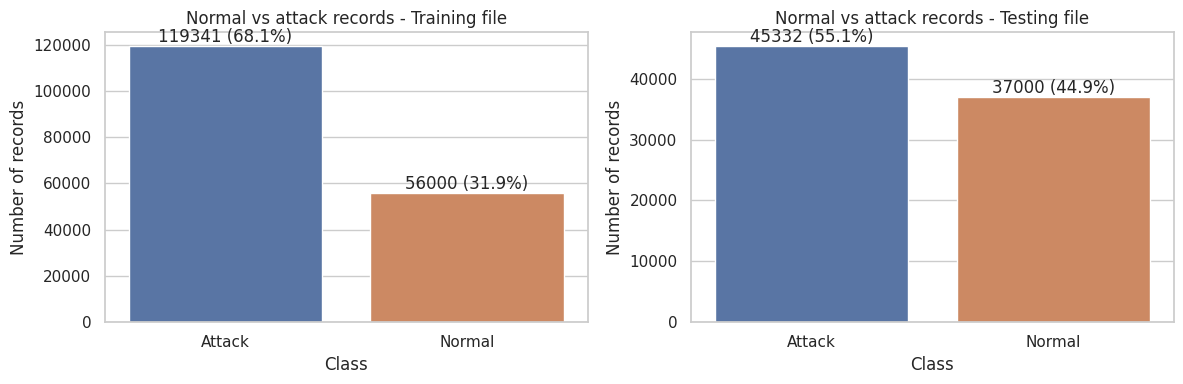

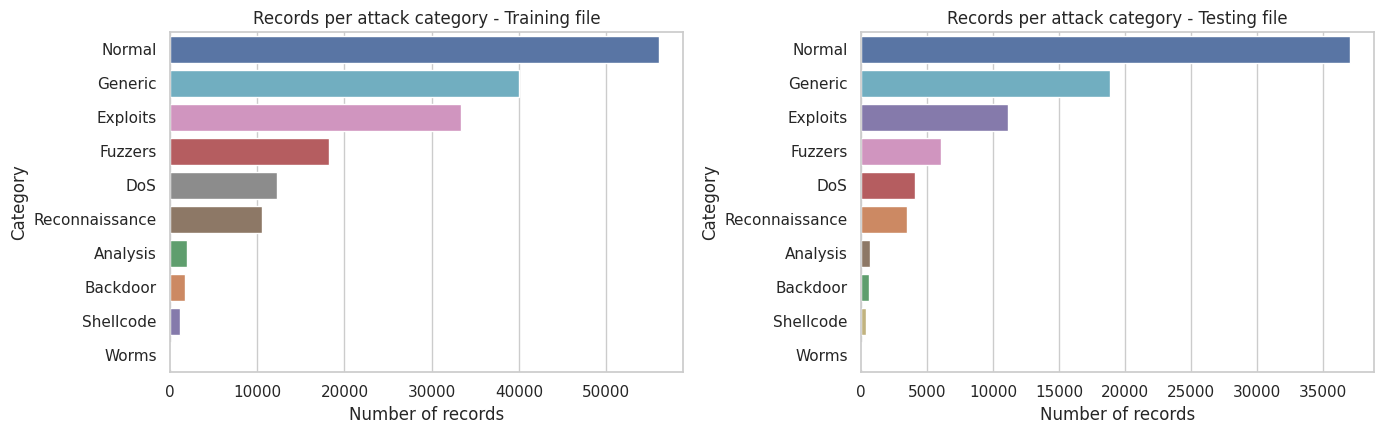

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (nm, df) in zip(axes, [("Training file", train_raw), ("Testing file", test_raw)]):
    counts = df["label"].map({0: "Normal", 1: "Attack"}).value_counts()
    sns.barplot(x=counts.index, y=counts.values, ax=ax, hue=counts.index, legend=False)
    ax.set_title(f"Normal vs attack records - {nm}")
    ax.set_xlabel("Class"); ax.set_ylabel("Number of records")
    for i, v in enumerate(counts.values):
        ax.text(i, v, f"{v} ({v/len(df)*100:.1f}%)", ha="center", va="bottom")
plt.tight_layout(); save_fig("01_binary_class_distribution.png"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=False)
for ax, (nm, df) in zip(axes, [("Training file", train_raw), ("Testing file", test_raw)]):
    order = df["attack_cat"].value_counts().index
    sns.countplot(y="attack_cat", data=df, order=order, ax=ax, hue="attack_cat", legend=False)
    ax.set_title(f"Records per attack category - {nm}")
    ax.set_xlabel("Number of records"); ax.set_ylabel("Category")
plt.tight_layout(); save_fig("02_attack_category_distribution.png"); plt.show()

*What to look for:* is one class much larger than the other? Are some attack categories very rare? Rare categories (for example Worms, Shellcode, Backdoor, Analysis) are usually the hardest for a model to detect. Also compare the class mix of the training and testing files: if it differs, a model can behave differently on the test file.

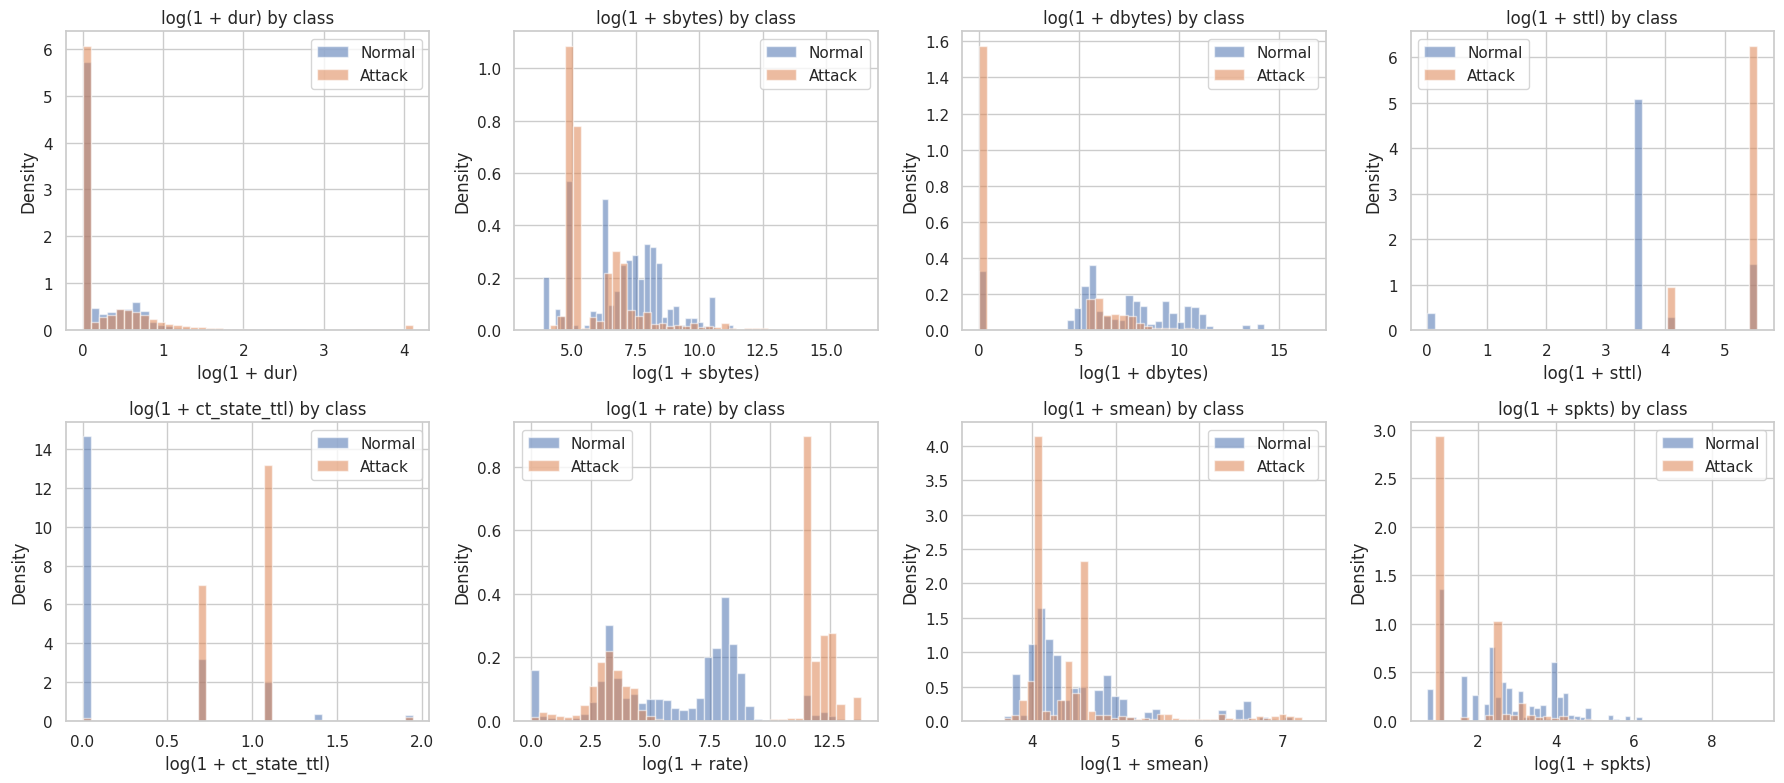

In [14]:
# Distributions of a few informative numeric features, normal vs attack (log scale because of heavy skew)
plot_feats = ["dur", "sbytes", "dbytes", "sttl", "ct_state_ttl", "rate", "smean", "spkts"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, f in zip(axes.ravel(), plot_feats):
    for lab, name in [(0, "Normal"), (1, "Attack")]:
        vals = train_raw.loc[train_raw.label == lab, f].astype(float)
        vals = vals.replace([np.inf, -np.inf], np.nan).dropna()
        ax.hist(np.log1p(vals.clip(lower=0)), bins=40, alpha=0.55, label=name, density=True)
    ax.set_title(f"log(1 + {f}) by class"); ax.set_xlabel(f"log(1 + {f})"); ax.set_ylabel("Density")
    ax.legend()
plt.tight_layout(); save_fig("03_feature_distributions.png"); plt.show()

*What to look for:* features where the Normal and Attack curves differ clearly are useful for classification. Overlapping curves mean the feature alone cannot separate the classes. This is visual evidence of *association*, not proof of cause.

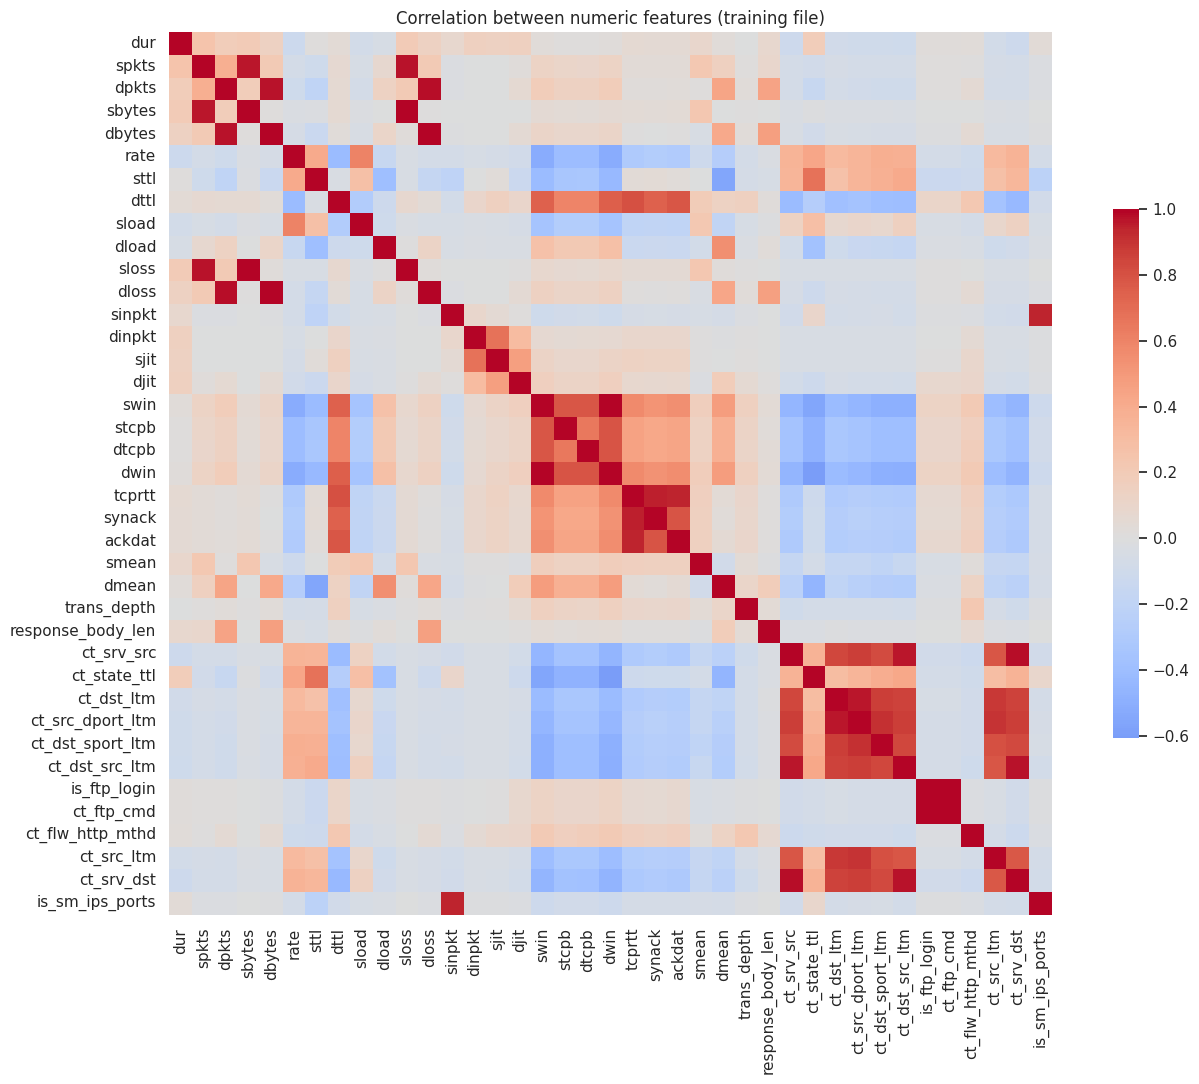

Top 10 numeric features by absolute correlation with the label (association only, not causation):


,correlation with label
sttl,0.693
ct_state_ttl,0.578
dload,-0.394
ct_dst_sport_ltm,0.357
dmean,-0.342
rate,0.338
swin,-0.334
dwin,-0.320
ct_src_dport_ltm,0.306
ct_dst_src_ltm,0.304


In [15]:
# Correlation heatmap of numeric features (training file)
num_cols_eda = [c for c in train_raw.select_dtypes(include=[np.number]).columns if c not in ["id", "label"]]
corr = train_raw[num_cols_eda].replace([np.inf, -np.inf], np.nan).corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": 0.6})
plt.title("Correlation between numeric features (training file)")
plt.tight_layout(); save_fig("04_correlation_heatmap.png"); plt.show()

# strongest correlations with the target label
target_corr = (train_raw[num_cols_eda + ["label"]].replace([np.inf, -np.inf], np.nan)
               .corr()["label"].drop("label").sort_values(key=np.abs, ascending=False).head(10))
print("Top 10 numeric features by absolute correlation with the label (association only, not causation):")
display(target_corr.round(3).to_frame("correlation with label"))

In [16]:
# ---------- leakage and contamination checks ----------
feat_for_hash = [c for c in train_raw.columns if c not in ["id", "attack_cat", "label"]]

h_train = pd.util.hash_pandas_object(train_raw[feat_for_hash], index=False)
h_test = pd.util.hash_pandas_object(test_raw[feat_for_hash], index=False)
overlap = int(np.isin(h_test.values, h_train.values).sum())
print(f"Test rows whose feature values are IDENTICAL to some training row: {overlap} "
      f"({overlap / len(test_raw) * 100:.2f}% of the test file)")

# categories present in test but never seen in training
for c in ["proto", "service", "state"]:
    unseen = sorted(set(test_raw[c].astype(str)) - set(train_raw[c].astype(str)))
    print(f"Categories of '{c}' in test but not in train: {unseen if unseen else 'none'}")

print("\n'attack_cat' maps almost one-to-one onto 'label', so it must NOT be used as an input feature:")
display(pd.crosstab(train_raw["attack_cat"], train_raw["label"]))

Test rows whose feature values are IDENTICAL to some training row: 8541 (10.37% of the test file)
Categories of 'proto' in test but not in train: none
Categories of 'service' in test but not in train: none
Categories of 'state' in test but not in train: ['ACC', 'CLO']

'attack_cat' maps almost one-to-one onto 'label', so it must NOT be used as an input feature:


label,0,1
attack_cat,,
Analysis,0,2000
Backdoor,0,1746
DoS,0,12264
Exploits,0,33393
Fuzzers,0,18184
Generic,0,40000
Normal,56000,0
Reconnaissance,0,10491
Shellcode,0,1133


## 5. Data cleaning decisions

Decisions are made from the counts printed above, not in advance:

* **Infinite values** (if any) are turned into missing values, then filled by the median *inside the pipeline* (fitted on training data only).
* **Duplicates:** the flag `DROP_TRAIN_DUPLICATES` in Section 1 controls whether exact duplicate training rows are removed. Look at the duplicate count in Section 3, decide, and write your justification in your report. The **test file is never de-duplicated**, so results stay comparable with the official test set.
* **Column types:** numeric columns are forced to numeric; categorical columns are converted to text.
* `id` is dropped (identifier). `attack_cat` is kept *outside* the feature table.

In [17]:
CAT_COLS = ["proto", "service", "state"]
DROP_FROM_FEATURES = ["id", "attack_cat", "label"]
FEATURE_COLS = [c for c in train_raw.columns if c not in DROP_FROM_FEATURES]
NUM_COLS = [c for c in FEATURE_COLS if c not in CAT_COLS]

def clean(df, name, drop_duplicates=False):
    out = df.copy(deep=True)
    # numeric columns -> numeric (count how many cells could not be converted)
    before_na = int(out[NUM_COLS].isna().sum().sum())
    for c in NUM_COLS:
        out[c] = pd.to_numeric(out[c], errors="coerce")
    coerced = int(out[NUM_COLS].isna().sum().sum()) - before_na
    # infinite -> NaN
    n_inf = int(np.isinf(out[NUM_COLS]).sum().sum())
    out[NUM_COLS] = out[NUM_COLS].replace([np.inf, -np.inf], np.nan)
    # categorical -> text; attack category -> tidy text
    for c in CAT_COLS:
        out[c] = out[c].astype(str).str.strip()
    out["attack_cat"] = out["attack_cat"].astype(str).str.strip()
    out["label"] = out["label"].astype(int)
    n_dup = int(out.duplicated(subset=FEATURE_COLS + ["label"]).sum())
    if drop_duplicates:
        out = out.drop_duplicates(subset=FEATURE_COLS + ["label"]).reset_index(drop=True)
    print(f"[{name}] non-numeric cells coerced to NaN: {coerced} | infinite cells set to NaN: {n_inf} | "
          f"duplicate rows found: {n_dup} | duplicates removed: {n_dup if drop_duplicates else 0} | final rows: {len(out)}")
    return out

train_df = clean(train_raw, "train", drop_duplicates=DROP_TRAIN_DUPLICATES)
test_df = clean(test_raw, "test", drop_duplicates=False)

[train] non-numeric cells coerced to NaN: 0 | infinite cells set to NaN: 0 | duplicate rows found: 74072 | duplicates removed: 0 | final rows: 175341
[test] non-numeric cells coerced to NaN: 0 | infinite cells set to NaN: 0 | duplicate rows found: 28380 | duplicates removed: 0 | final rows: 82332


## 6. Feature and target separation, and the train/test split

We use the **official split**: the provided training file is for training and tuning; the provided testing file is used **once** at the end. This keeps the test data separate and matches the setup in the literature.

* **X** = the 42 flow features (after dropping `id`, `attack_cat`, `label`)
* **y** = `label` (0 = normal, 1 = attack)
* `attack_cat` of the test file is stored separately, only for the per-category error analysis in Section 10.

In [18]:
X_train, y_train = train_df[FEATURE_COLS], train_df["label"]
X_test, y_test = test_df[FEATURE_COLS], test_df["label"]
test_attack_cat = test_df["attack_cat"].reset_index(drop=True)

# ---------- sanity checks ----------
assert list(X_train.columns) == list(X_test.columns), "train and test feature columns differ"
assert "label" not in X_train.columns and "attack_cat" not in X_train.columns and "id" not in X_train.columns
assert set(y_train.unique()) <= {0, 1} and set(y_test.unique()) <= {0, 1}
assert len(X_train) == len(y_train) and len(X_test) == len(y_test)
print("Features:", X_train.shape[1], "| numeric:", len(NUM_COLS), "| categorical:", len(CAT_COLS))
print("Training rows:", len(X_train), "| Testing rows:", len(X_test))
print("Train class share (attack): %.2f%% | Test class share (attack): %.2f%%" % (y_train.mean()*100, y_test.mean()*100))
print("Train/test separation: the test file was never used to fit anything so far.")

Features: 42 | numeric: 39 | categorical: 3
Training rows: 175341 | Testing rows: 82332
Train class share (attack): 68.06% | Test class share (attack): 55.06%
Train/test separation: the test file was never used to fit anything so far.


## 7. Preprocessing pipeline, models and hyperparameters

### Why a pipeline?
A scikit-learn `Pipeline` bundles preprocessing and the model. During cross-validation the preprocessing is re-fitted on each training fold only, so information from the validation fold (or the test file) never leaks into training.

### Preprocessing steps
| Step | Applied to | Reason |
|---|---|---|
| Median imputation | numeric columns | fills any missing/infinite cells without using test data |
| Standard scaling | numeric columns, **Logistic Regression only** | linear models are sensitive to feature scale; trees are not |
| One-hot encoding (`handle_unknown='ignore'`) | `proto`, `service`, `state` | turns categories into 0/1 columns; categories unseen in training become all zeros instead of crashing |

### Models
| Model | Role | How it works (simple) | Weakness |
|---|---|---|---|
| Dummy baseline | reference | always predicts the most common training class | learns nothing |
| Logistic Regression | simple linear baseline | combines features with weights into a probability of attack | assumes a roughly linear boundary |
| Decision Tree | interpretable rules | asks a sequence of yes/no questions about features | overfits if too deep |
| Random Forest (main model) | strong non-linear model | many trees trained on random subsets vote together | slower, harder to explain |

### Hyperparameters (set before training) vs parameters (learned during training)
* **Parameters:** regression coefficients, tree split points.
* **Hyperparameters:** `C` (Logistic Regression regularisation strength; smaller = simpler model), `max_depth` (how deep a tree may grow), `min_samples_leaf` (minimum records in a leaf; larger = simpler), `n_estimators` (number of trees), `max_features` (features considered at each split).
* **Training setting:** random seed. **Evaluation threshold:** probability cut-off (0.5 by default) that turns a score into "attack".

The search grids below are small on purpose so the notebook runs on free Colab. The final values are chosen by cross-validation on the **training file only**, scored by F1 of the attack class.

In [19]:
def make_pipeline(model, scale):
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("scaler", StandardScaler()))
    pre = ColumnTransformer([
        ("num", Pipeline(num_steps), NUM_COLS),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS),
    ])
    return Pipeline([("prep", pre), ("model", model)])

model_specs = {
    "Logistic Regression": dict(
        pipe=make_pipeline(LogisticRegression(max_iter=2000, random_state=SEED), scale=True),
        grid={"model__C": [0.1, 1.0, 10.0]},
        grid_jobs=-1),
    "Decision Tree": dict(
        pipe=make_pipeline(DecisionTreeClassifier(random_state=SEED), scale=False),
        grid={"model__max_depth": [5, 10, 20, None], "model__min_samples_leaf": [1, 5, 20]},
        grid_jobs=-1),
    "Random Forest": dict(
        pipe=make_pipeline(RandomForestClassifier(random_state=SEED, n_jobs=-1), scale=False),
        grid={"model__n_estimators": [100], "model__max_depth": [15, None],
              "model__min_samples_leaf": [1, 5], "model__max_features": ["sqrt"]},
        grid_jobs=1),   # the forest itself already uses all CPU cores
}
for k, v in model_specs.items():
    n_combo = int(np.prod([len(x) for x in v["grid"].values()]))
    print(f"{k}: {n_combo} hyperparameter combinations x {CV_FOLDS} folds")

Logistic Regression: 3 hyperparameter combinations x 5 folds
Decision Tree: 12 hyperparameter combinations x 5 folds
Random Forest: 4 hyperparameter combinations x 5 folds


## 8. Training

First the **baseline**, then each model is tuned with stratified cross-validation on the training file. `GridSearchCV` tries every combination, scores each by mean F1 across folds, then refits the best one on the whole training file.

*Note on cross-validation:* CV happens inside the training file, so its scores can look more optimistic than the score on the official test file if the two files differ in traffic mix. Section 9 shows both side by side.

In [22]:
# ---------- baseline: always predict the most common training class ----------
baseline = make_pipeline(DummyClassifier(strategy="most_frequent"), scale=False)
baseline.fit(X_train, y_train)
print("Baseline predicts class:", int(baseline.predict(X_test[:1])[0]),
      "(1 = attack). Because attacks are the majority of the TRAINING file, it may label everything as attack.")

# ---------- tune and train the three models ----------
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
searches, fit_times = {}, {}
for name, spec in model_specs.items():
    print(f"\n=== Training {name} ===")
    t0 = time.time()
    gs = GridSearchCV(spec["pipe"], spec["grid"], cv=cv, scoring="f1",
                      n_jobs=spec["grid_jobs"], refit=True, return_train_score=False)
    gs.fit(X_train, y_train)
    fit_times[name] = time.time() - t0
    searches[name] = gs
    print("Best hyperparameters:", gs.best_params_)
    print(f"Best mean CV F1 (attack class, training file only): {gs.best_score_:.4f}")
    print(f"Total tuning + training time: {fit_times[name]:.1f} s")

Baseline predicts class: 1 (1 = attack). Because attacks are the majority of the TRAINING file, it may label everything as attack.

=== Training Logistic Regression ===
Best hyperparameters: {'model__C': 10.0}
Best mean CV F1 (attack class, training file only): 0.9546
Total tuning + training time: 85.8 s

=== Training Decision Tree ===
Best hyperparameters: {'model__max_depth': 20, 'model__min_samples_leaf': 1}
Best mean CV F1 (attack class, training file only): 0.9635
Total tuning + training time: 221.2 s

=== Training Random Forest ===
Best hyperparameters: {'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'model__n_estimators': 100}
Best mean CV F1 (attack class, training file only): 0.9703
Total tuning + training time: 1076.5 s


## 9. Evaluation on the official test file

Each final model is evaluated **once** on the untouched test file. The metrics, with intrusion-detection meaning (attack = positive class):

| Metric | Formula | Meaning here |
|---|---|---|
| Accuracy | (TP+TN) / all | share of all flows classified correctly (can mislead when classes are unequal) |
| Precision | TP / (TP+FP) | of flows flagged as attacks, how many really were |
| Recall (detection rate) | TP / (TP+FN) | of real attacks, how many were caught |
| F1-score | 2PR / (P+R) | balance of precision and recall |
| False-positive rate | FP / (FP+TN) | normal traffic wrongly flagged (false alarms) |
| False-negative rate | FN / (FN+TP) | attacks missed (the dangerous error) |
| ROC-AUC / PR-AUC | area under curves | ranking quality across all thresholds |

TP = attack caught, TN = normal passed, FP = false alarm, FN = missed attack.

In [23]:
def evaluate(model, X, y):
    t0 = time.time()
    y_pred = model.predict(X)
    pred_time = time.time() - t0
    score = model.predict_proba(X)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y, y_pred, labels=[0, 1]).ravel()
    return {
        "Accuracy": accuracy_score(y, y_pred),
        "Precision": precision_score(y, y_pred, zero_division=0),
        "Recall": recall_score(y, y_pred, zero_division=0),
        "F1": f1_score(y, y_pred, zero_division=0),
        "FPR": fp / (fp + tn) if (fp + tn) else np.nan,
        "FNR": fn / (fn + tp) if (fn + tp) else np.nan,
        "ROC-AUC": roc_auc_score(y, score),
        "PR-AUC": average_precision_score(y, score),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        "Predict time (s)": pred_time,
        "_pred": y_pred, "_score": score,
    }

final_models = {"Baseline (majority class)": baseline}
final_models.update({k: v.best_estimator_ for k, v in searches.items()})

results = {name: evaluate(m, X_test, y_test) for name, m in final_models.items()}

metric_cols = ["Accuracy", "Precision", "Recall", "F1", "FPR", "FNR", "ROC-AUC", "PR-AUC"]
results_df = pd.DataFrame({k: {m: v[m] for m in metric_cols} for k, v in results.items()}).T
print("Model comparison on the OFFICIAL TEST FILE (positive class = attack):")
display(results_df.round(4))

Model comparison on the OFFICIAL TEST FILE (positive class = attack):


,Accuracy,Precision,Recall,F1,FPR,FNR,ROC-AUC,PR-AUC
Baseline (majority class),0.5506,0.5506,1.0000,0.7102,1.0000,0.0000,0.5000,0.5506
Logistic Regression,0.8110,0.7549,0.9725,0.8500,0.3869,0.0275,0.9562,0.9664
Decision Tree,0.8693,0.8300,0.9590,0.8899,0.2407,0.0410,0.8970,0.8656
Random Forest,0.8719,0.8188,0.9853,0.8944,0.2671,0.0147,0.9783,0.9813


In [24]:
for name in ["Logistic Regression", "Decision Tree", "Random Forest"]:
    print("=" * 70); print(name, "- classification report (test file)")
    print(classification_report(y_test, results[name]["_pred"], target_names=["Normal", "Attack"], digits=4))

Logistic Regression - classification report (test file)
              precision    recall  f1-score   support

      Normal     0.9479    0.6131    0.7446     37000
      Attack     0.7549    0.9725    0.8500     45332

    accuracy                         0.8110     82332
   macro avg     0.8514    0.7928    0.7973     82332
weighted avg     0.8416    0.8110    0.8026     82332

Decision Tree - classification report (test file)
              precision    recall  f1-score   support

      Normal     0.9380    0.7593    0.8392     37000
      Attack     0.8300    0.9590    0.8899     45332

    accuracy                         0.8693     82332
   macro avg     0.8840    0.8592    0.8645     82332
weighted avg     0.8785    0.8693    0.8671     82332

Random Forest - classification report (test file)
              precision    recall  f1-score   support

      Normal     0.9760    0.7329    0.8372     37000
      Attack     0.8188    0.9853    0.8944     45332

    accuracy              

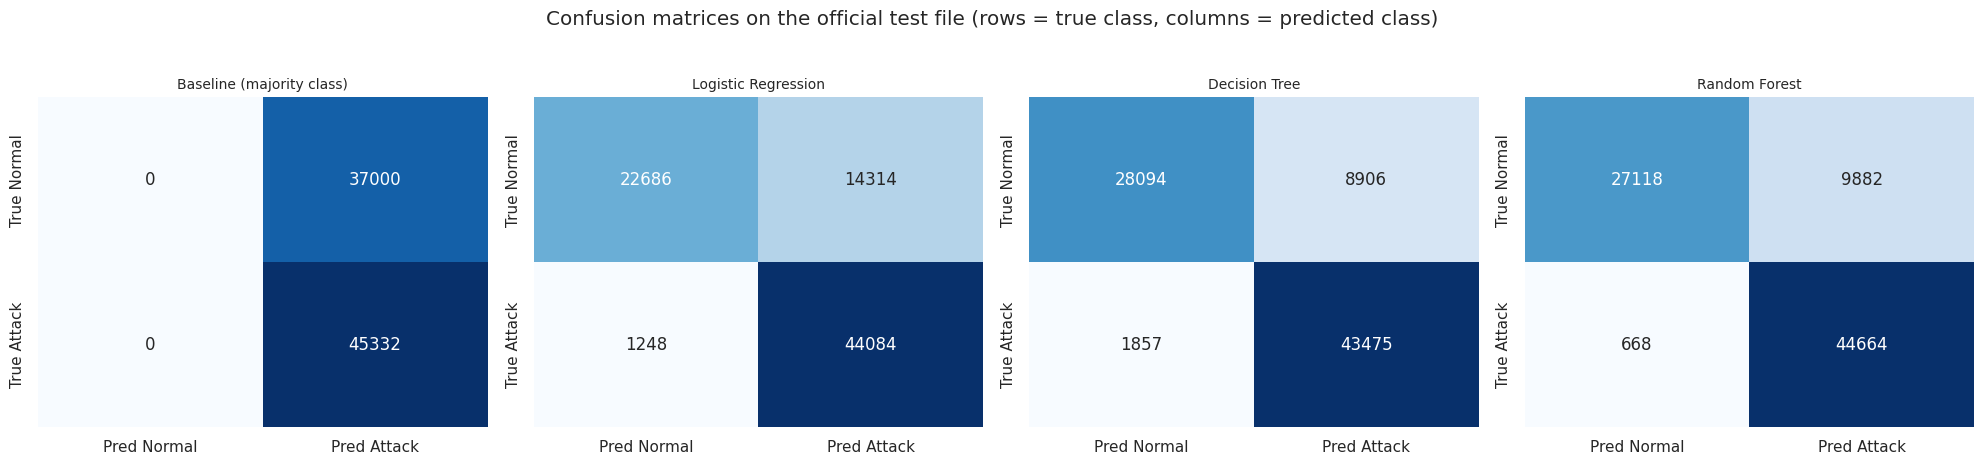

In [25]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, name in zip(axes, results.keys()):
    cm = np.array([[results[name]["TN"], results[name]["FP"]], [results[name]["FN"], results[name]["TP"]]])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Pred Normal", "Pred Attack"], yticklabels=["True Normal", "True Attack"])
    ax.set_title(name, fontsize=10)
plt.suptitle("Confusion matrices on the official test file (rows = true class, columns = predicted class)", y=1.03)
plt.tight_layout(); save_fig("05_confusion_matrices.png"); plt.show()

*How to read a confusion matrix:* top-right = **false positives** (normal flagged as attack, false alarms); bottom-left = **false negatives** (attacks that slipped through). In a security setting, a missed attack and a false alarm have different costs; compare the two off-diagonal cells for each model.

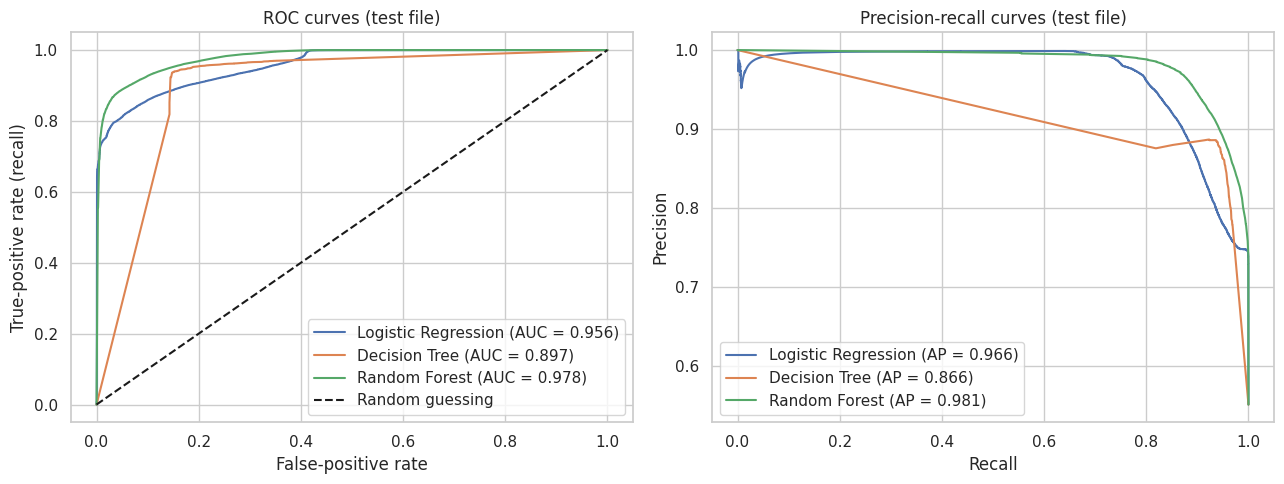

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name in ["Logistic Regression", "Decision Tree", "Random Forest"]:
    fpr, tpr, _ = roc_curve(y_test, results[name]["_score"])
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {results[name]['ROC-AUC']:.3f})")
    prec, rec, _ = precision_recall_curve(y_test, results[name]["_score"])
    axes[1].plot(rec, prec, label=f"{name} (AP = {results[name]['PR-AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="Random guessing")
axes[0].set_title("ROC curves (test file)"); axes[0].set_xlabel("False-positive rate"); axes[0].set_ylabel("True-positive rate (recall)"); axes[0].legend()
axes[1].set_title("Precision-recall curves (test file)"); axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].legend()
plt.tight_layout(); save_fig("06_roc_pr_curves.png"); plt.show()

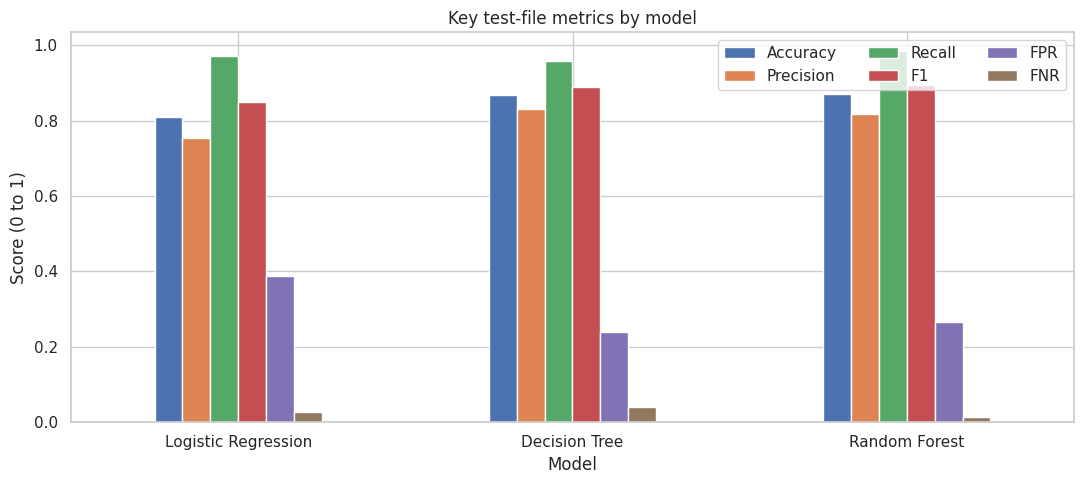

In [27]:
# bar chart comparing key metrics
plot_df = results_df.loc[["Logistic Regression", "Decision Tree", "Random Forest"], ["Accuracy", "Precision", "Recall", "F1", "FPR", "FNR"]]
plot_df.plot(kind="bar", figsize=(11, 5), rot=0)
plt.title("Key test-file metrics by model"); plt.ylabel("Score (0 to 1)"); plt.xlabel("Model"); plt.legend(loc="upper right", ncol=3)
plt.tight_layout(); save_fig("07_model_metric_comparison.png"); plt.show()

## 10. Error analysis by attack category

The binary model only says "attack" or "normal", but the test file also records *which* attack each record is. For every attack category we compute the **detection rate** (share of that category predicted as attack). For the `Normal` row, we show the share **correctly passed** (specificity); one minus that is the false-alarm rate.
Rare categories usually show the weakest detection rates; this connects to the findings of Ngo et al. (2023).

Detection rate per attack category (for 'Normal': share correctly passed):


,Test records,Logistic Regression,Decision Tree,Random Forest
Category,,,,
Analysis,677,0.9143,0.9394,1.0000
Backdoor,583,0.9897,0.9931,1.0000
DoS,4089,0.9790,0.9868,0.9993
Exploits,11132,0.9429,0.9759,0.9958
Fuzzers,6062,0.9301,0.7794,0.8987
Generic,18871,0.9990,0.9956,1.0000
Normal,37000,0.6131,0.7593,0.7329
Reconnaissance,3496,0.9963,0.9854,0.9997
Shellcode,378,0.9868,0.9524,0.9921


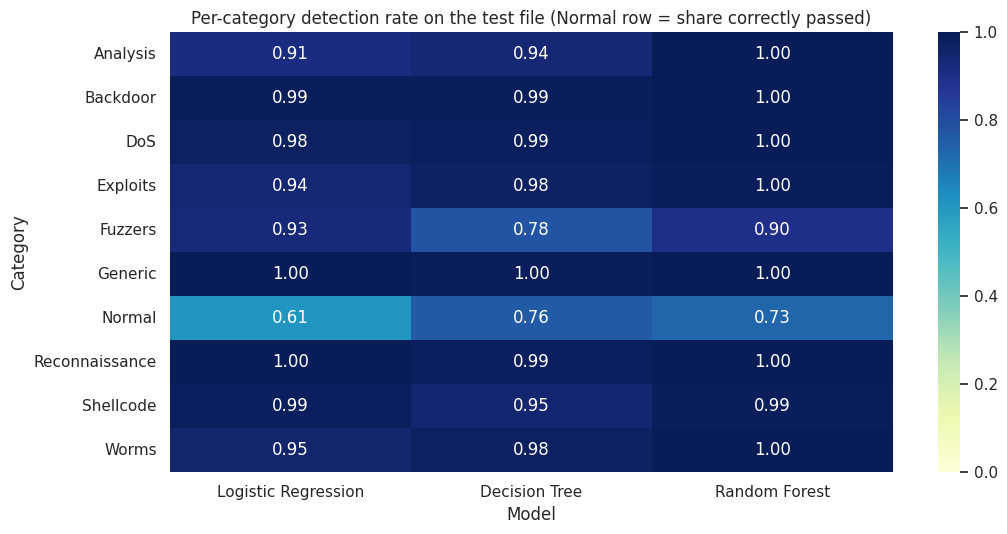

In [28]:
def per_category_table(preds_dict):
    rows = []
    for cat in sorted(test_attack_cat.unique()):
        mask = (test_attack_cat == cat).values
        row = {"Category": cat, "Test records": int(mask.sum())}
        for name, pred in preds_dict.items():
            pred = np.asarray(pred)
            if cat == "Normal":
                row[name] = float((pred[mask] == 0).mean())    # correctly passed
            else:
                row[name] = float((pred[mask] == 1).mean())    # detected
        rows.append(row)
    return pd.DataFrame(rows).set_index("Category")

preds = {n: results[n]["_pred"] for n in ["Logistic Regression", "Decision Tree", "Random Forest"]}
per_cat = per_category_table(preds)
print("Detection rate per attack category (for 'Normal': share correctly passed):")
display(per_cat.round(4))

plt.figure(figsize=(11, 5.5))
sns.heatmap(per_cat.drop(columns="Test records"), annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1)
plt.title("Per-category detection rate on the test file (Normal row = share correctly passed)")
plt.ylabel("Category"); plt.xlabel("Model")
plt.tight_layout(); save_fig("08_per_category_detection.png"); plt.show()

### Overfitting check and the random-split contrast

*Overfitting* means a model memorises the training data and does worse on new data. We compare three scores for each model: the mean **cross-validation** F1 (training file), the F1 on the **whole training file** (the model has seen it), and the F1 on the **official test file**. A large gap between training and test F1 is a warning sign; a gap between CV and test F1 means the test file differs from the training file.

The *random-split contrast* (optional) retrains the tuned Random Forest on a random 80% of the training file and tests it on the remaining 20%. If this score is much higher than the official test score, it shows how a random split can give an **unrealistically optimistic** result.

In [29]:
rows = []
for name in ["Logistic Regression", "Decision Tree", "Random Forest"]:
    train_f1 = f1_score(y_train, final_models[name].predict(X_train))
    rows.append({"Model": name,
                 "Mean CV F1 (train file)": searches[name].best_score_,
                 "F1 on full train file": train_f1,
                 "F1 on official test file": results[name]["F1"],
                 "Train minus test F1": train_f1 - results[name]["F1"]})
overfit_df = pd.DataFrame(rows).set_index("Model")
display(overfit_df.round(4))

contrast_f1 = None
if RUN_RANDOM_SPLIT_CONTRAST:
    Xa, Xb, ya, yb = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=SEED)
    rf_clone = clone(searches["Random Forest"].best_estimator_).fit(Xa, ya)
    contrast_f1 = f1_score(yb, rf_clone.predict(Xb))
    print(f"Random Forest, random 80/20 split INSIDE the training file: F1 = {contrast_f1:.4f}")
    print(f"Random Forest, official test file                       : F1 = {results['Random Forest']['F1']:.4f}")

,Mean CV F1 (train file),F1 on full train file,F1 on official test file,Train minus test F1
Model,,,,
Logistic Regression,0.9546,0.9548,0.8500,0.1048
Decision Tree,0.9635,0.9853,0.8899,0.0954
Random Forest,0.9703,0.9987,0.8944,0.1043


Random Forest, random 80/20 split INSIDE the training file: F1 = 0.9702
Random Forest, official test file                       : F1 = 0.8944


## 11. Model interpretation: feature importance

* **Random Forest impurity importance** shows how much each (encoded) feature reduced impurity across the trees. It can favour features with many distinct values.
* **Permutation importance** shuffles one original feature at a time on a test subsample and measures how much F1 drops; a bigger drop means the model relied on that feature more.
* **Logistic Regression coefficients** (on scaled features) show the direction and relative size of each feature's effect inside that linear model.

**Important:** importance shows what the *model uses*, not what *causes* an attack. A strongly important feature may also reflect how this lab dataset was generated (for example `sttl` was dominant in Kasongo & Sun, 2020), which may not hold on other networks.

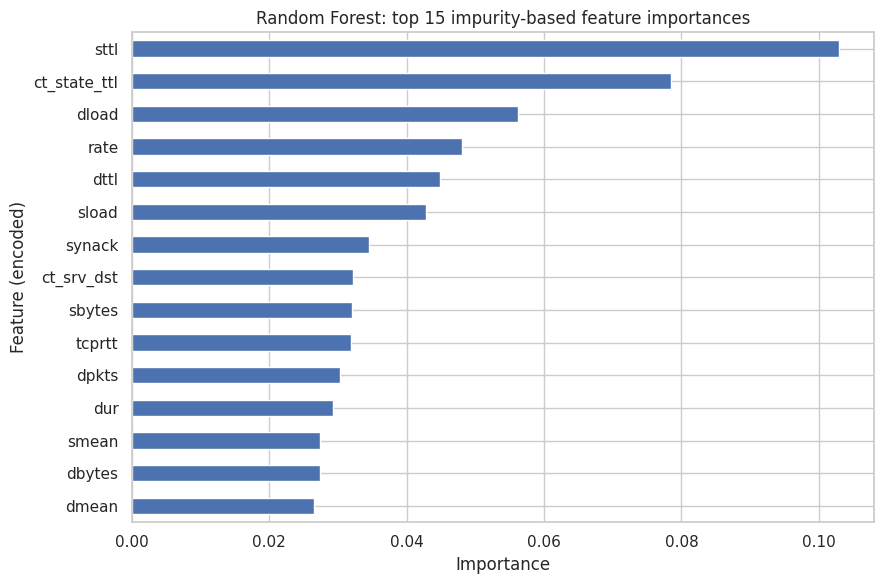

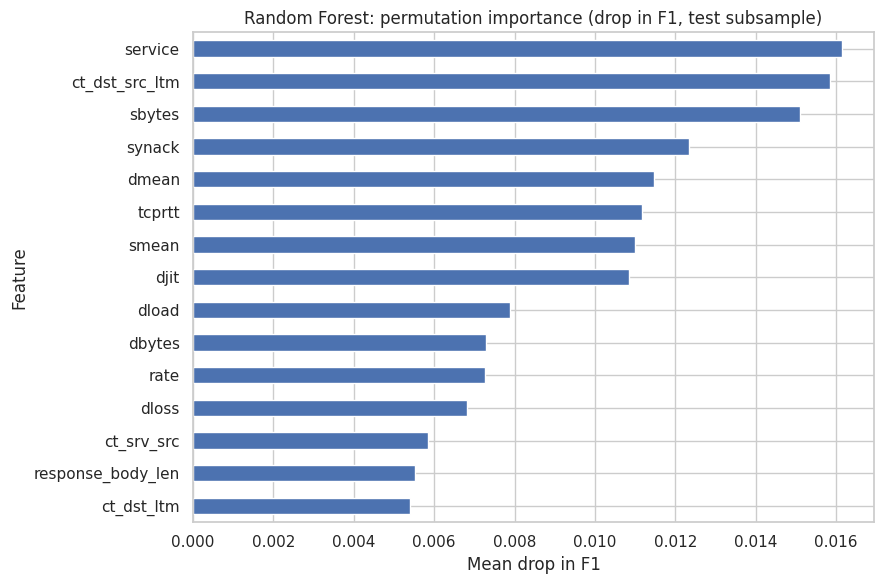

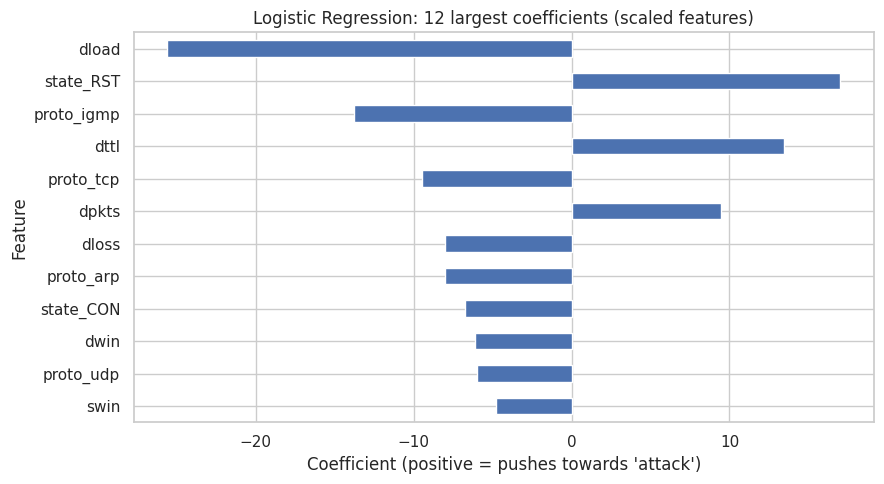

In [30]:
rf_pipe = final_models["Random Forest"]
feat_names = [n.split("__", 1)[1] for n in rf_pipe.named_steps["prep"].get_feature_names_out()]
imp = pd.Series(rf_pipe.named_steps["model"].feature_importances_, index=feat_names).sort_values(ascending=False)

plt.figure(figsize=(9, 6))
imp.head(15)[::-1].plot(kind="barh")
plt.title("Random Forest: top 15 impurity-based feature importances")
plt.xlabel("Importance"); plt.ylabel("Feature (encoded)")
plt.tight_layout(); save_fig("09_rf_feature_importance.png"); plt.show()

# permutation importance on original (un-encoded) features, using a test subsample
rng_idx = np.random.RandomState(SEED).choice(len(X_test), size=min(PERM_SAMPLE, len(X_test)), replace=False)
perm = permutation_importance(rf_pipe, X_test.iloc[rng_idx], y_test.iloc[rng_idx], scoring="f1",
                              n_repeats=3, random_state=SEED, n_jobs=-1)
perm_s = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
plt.figure(figsize=(9, 6))
perm_s.head(15)[::-1].plot(kind="barh")
plt.title("Random Forest: permutation importance (drop in F1, test subsample)")
plt.xlabel("Mean drop in F1"); plt.ylabel("Feature")
plt.tight_layout(); save_fig("10_rf_permutation_importance.png"); plt.show()

# logistic regression coefficients
lr_pipe = final_models["Logistic Regression"]
lr_names = [n.split("__", 1)[1] for n in lr_pipe.named_steps["prep"].get_feature_names_out()]
coef = pd.Series(lr_pipe.named_steps["model"].coef_[0], index=lr_names)
top_coef = coef.reindex(coef.abs().sort_values(ascending=False).head(12).index)
plt.figure(figsize=(9, 5))
top_coef[::-1].plot(kind="barh")
plt.title("Logistic Regression: 12 largest coefficients (scaled features)")
plt.xlabel("Coefficient (positive = pushes towards 'attack')"); plt.ylabel("Feature")
plt.tight_layout(); save_fig("11_lr_coefficients.png"); plt.show()

## 12. Results, comparison and discussion

The next cell builds a factual summary **from your own run** and saves tables and figures into the `outputs/` folder. These saved files will be used to produce the results sections of the PDF guide, so keep them.

In [31]:
cand = ["Logistic Regression", "Decision Tree", "Random Forest"]
best_f1 = results_df.loc[cand, "F1"].idxmax()
low_fnr = results_df.loc[cand, "FNR"].idxmin()
low_fpr = results_df.loc[cand, "FPR"].idxmin()
base_acc = results_df.loc["Baseline (majority class)", "Accuracy"]

print("AUTOMATIC SUMMARY OF THIS RUN (test file)")
print(f"- Baseline (majority class) accuracy: {base_acc:.4f}")
print(f"- Highest F1: {best_f1} ({results_df.loc[best_f1, 'F1']:.4f})")
print(f"- Fewest missed attacks (lowest FNR): {low_fnr} ({results_df.loc[low_fnr, 'FNR']:.4f})")
print(f"- Fewest false alarms (lowest FPR): {low_fpr} ({results_df.loc[low_fpr, 'FPR']:.4f})")
weak = per_cat.drop(index="Normal", errors="ignore").drop(columns="Test records").mean(axis=1).sort_values().head(3)
print("- Attack categories with the lowest average detection rate across the 3 models:")
for cat, v in weak.items():
    print(f"    {cat}: {v:.3f}  ({int(per_cat.loc[cat, 'Test records'])} test records)")

# ---------- save everything needed for the report ----------
results_df.round(6).to_csv(os.path.join(OUT_DIR, "model_comparison_test.csv"))
per_cat.round(6).to_csv(os.path.join(OUT_DIR, "per_category_detection.csv"))
overfit_df.round(6).to_csv(os.path.join(OUT_DIR, "overfitting_check.csv"))
pd.DataFrame({k: {m: results[k][m] for m in ["TN", "FP", "FN", "TP"]} for k in results}).T.to_csv(
    os.path.join(OUT_DIR, "confusion_counts.csv"))
imp.head(20).to_csv(os.path.join(OUT_DIR, "rf_impurity_importance.csv"))
perm_s.head(20).to_csv(os.path.join(OUT_DIR, "rf_permutation_importance.csv"))
meta = {
    "seed": SEED, "cv_folds": CV_FOLDS, "drop_train_duplicates": DROP_TRAIN_DUPLICATES,
    "train_rows_used": int(len(X_train)), "test_rows": int(len(X_test)),
    "train_attack_share": float(y_train.mean()), "test_attack_share": float(y_test.mean()),
    "test_rows_identical_to_train_rows": overlap,
    "best_params": {k: {p: (None if v is None else (v if isinstance(v, (int, float, str)) else str(v)))
                        for p, v in searches[k].best_params_.items()} for k in searches},
    "mean_cv_f1": {k: float(searches[k].best_score_) for k in searches},
    "tuning_time_seconds": {k: float(v) for k, v in fit_times.items()},
    "random_split_contrast_f1_rf": None if contrast_f1 is None else float(contrast_f1),
    "versions": {"pandas": pd.__version__, "numpy": np.__version__, "scikit-learn": sklearn.__version__},
}
with open(os.path.join(OUT_DIR, "run_metadata.json"), "w") as f:
    json.dump(meta, f, indent=2)
print("\nSaved tables, figures and metadata in:", os.path.abspath(OUT_DIR))

AUTOMATIC SUMMARY OF THIS RUN (test file)
- Baseline (majority class) accuracy: 0.5506
- Highest F1: Random Forest (0.8944)
- Fewest missed attacks (lowest FNR): Random Forest (0.0147)
- Fewest false alarms (lowest FPR): Decision Tree (0.2407)
- Attack categories with the lowest average detection rate across the 3 models:
    Fuzzers: 0.869  (6062 test records)
    Analysis: 0.951  (677 test records)
    Exploits: 0.972  (11132 test records)

Saved tables, figures and metadata in: /content/outputs


### Discussion (write this from YOUR numbers)

Answer these questions in your own words using the tables and plots above. Do not copy numbers from the research papers as if you obtained them.

1. **Which model had the highest F1 on the test file, and by how much compared with the baseline?** If the baseline is already strong, what does that say about accuracy as a metric here?
2. **Compare false-positive and false-negative rates.** Which model would create the most alert fatigue? Which would let the most attacks through?
3. **Training vs test gap.** Is there a large gap between training F1, CV F1 and test F1? What could explain it (overfitting, different class mix in the test file, different attack behaviour)?
4. **Per-category results.** Which attack categories are detected well, and which badly? Is the weak detection linked to how few training examples exist?
5. **Feature importance.** Which features matter most? Does the same feature appear in both impurity and permutation importance? Remember: this is association, not cause.
6. **Random-split contrast.** Is the random 80/20 score higher than the official test score? What does that tell you about how the data is split?
7. **Relation to the literature.** Your setup (preprocessing, split, tuning) differs from the five papers, so compare only the general pattern (for example rare classes being missed, or a train/test gap), **not exact numbers**.

## Limitations

* **One dataset, created in a laboratory (2015).** Traffic and attacks may not resemble today's real networks. The cross-dataset studies by Layeghy & Portmann (2022) and Hossain et al. (2026) report large performance drops on other datasets.
* **Synthetic attacks and labels.** Attack traffic was generated with a tool; real attackers behave differently.
* **Offline classification.** Records are classified after the fact; a real IDS must work in real time on streaming traffic with limited resources.
* **Binary view.** The models only separate normal from attack; they do not name the attack type.
* **Rare attack classes** have few examples, so detection estimates for them are unreliable.
* **Train/test differences.** The official files have different class mixes, and a few feature values or categories may appear only in one file.
* **No concept-drift test.** We did not study how performance changes as attacks evolve.
* **Limited tuning.** Small grids were used to fit Colab limits; more tuning might change the ranking slightly.
* **Feature importance is not causation.**
* **Possible hidden duplicates or near-duplicates** between train and test can inflate results; see the overlap check in Section 4.

## Conclusion (complete after you have run the notebook)

Use this structure and fill the blanks from your own outputs:

*This project compared Logistic Regression, Decision Tree and Random Forest for classifying network flows from the official UNSW-NB15 training and testing files as normal or attack. After tuning with ___-fold cross-validation on the training file only, the best model on the test file was ___ with F1 = ___, a false-positive rate of ___ and a false-negative rate of ___. The majority-class baseline reached accuracy ___. Detection was weakest for the categories ___ and ___. The most influential features were ___. A gap of ___ between training and test F1 suggests ___. These results come from a single, laboratory-generated, 2015 dataset and an offline experiment, so they do not show how the models would perform on a live network. Future work could include cross-dataset testing, techniques for rare classes, probability-threshold selection, and streaming detection.*

## References

1. Moustafa, N., & Slay, J. (2015). UNSW-NB15: a comprehensive data set for network intrusion detection systems (UNSW-NB15 network data set). *2015 Military Communications and Information Systems Conference (MilCIS)*, pp. 1-6. https://doi.org/10.1109/MilCIS.2015.7348942
2. Moustafa, N., & Slay, J. (2016). The evaluation of network anomaly detection systems: Statistical analysis of the UNSW-NB15 data set and the comparison with the KDD99 data set. *Information Security Journal: A Global Perspective*, 25(1-3), 18-31.
3. Other papers and the thesis that the dataset owners ask users to cite are listed at the official page: https://research.unsw.edu.au/projects/unsw-nb15-dataset (cite exactly as listed there).
4. Kasongo, S. M., & Sun, Y. (2020). Performance analysis of intrusion detection systems using a feature selection method on the UNSW-NB15 dataset. *Journal of Big Data*, 7, 105. https://doi.org/10.1186/s40537-020-00379-6  *(confirm full author names on the article page)*
5. Ngo, V.-D., Vuong, T.-C., Luong, T. V., & Tran, H. (2023). Machine Learning-Based Intrusion Detection: Feature Selection versus Feature Extraction. arXiv:2307.01570 (preprint). https://arxiv.org/abs/2307.01570
6. Layeghy, S., & Portmann, M. (2022). On Generalisability of Machine Learning-based Network Intrusion Detection Systems. arXiv:2205.04112 (preprint). https://arxiv.org/abs/2205.04112
7. Hossain, M. Z., Khan, M. A. R., Islam, M. R., Islam, S. M. S., & Gedeon, T. (2026). Assessing Generalisation Capability of Machine Learning Models for Intrusion Detection. arXiv:2605.04407 (preprint, v1, 6 May 2026). https://arxiv.org/abs/2605.04407
8. Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825-2830.

## Likely viva questions (short answers; a full set of 60+ will be in the viva guide)

1. **What is the target column?** `label`: 0 = normal, 1 = attack.
2. **Why did you drop `attack_cat` from the inputs?** It names the attack, so it would give the answer away (data leakage).
3. **Why did you choose UNSW-NB15?** Modern-style traffic, labelled normal and attack records, a ready-made train/test split, a size that fits Colab, a clear academic-use licence.
4. **Why is accuracy not enough?** With unequal classes a model can score high accuracy while missing a whole attack type; so I report precision, recall, F1, false-positive and false-negative rates.
5. **False positive vs false negative?** False positive = normal flagged as attack (false alarm); false negative = attack missed.
6. **How did you prevent leakage?** Preprocessing is inside a pipeline fitted on training data only; tuning uses cross-validation inside the training file; the test file is used once at the end; `attack_cat`, `label` and `id` are excluded from the inputs.
7. **How do you know whether it is overfitting?** I compare training F1, cross-validation F1 and test F1; a large training-minus-test gap is a warning sign.
8. **Why Random Forest?** It handles mixed features and non-linear patterns and is usually more stable than one tree, at the cost of interpretability.
9. **Why scale features only for Logistic Regression?** Linear models depend on feature scale; tree models do not.
10. **What are hyperparameters?** Settings chosen before training (for example `max_depth`, `C`); parameters are learned from data.
11. **What happens with an attack type absent from training?** The model may call it normal; this experiment does not test unseen attack types.
12. **Is the result reproducible?** The random seed is fixed and library versions are saved in `run_metadata.json`.
13. **Can this be used on a real network?** Not proven; it is a benchmark experiment on 2015 laboratory data.
14. **What does the confusion matrix show?** Correct and wrong predictions for each class, especially false alarms and missed attacks.
15. **What exactly did you contribute?** (Answer honestly in your own words: dataset selection, pipeline design, experiments, interpretation.)

In [32]:
# OPTIONAL: bundle the saved tables and figures into one zip file (Colab: downloads it to your computer)
zip_path = shutil.make_archive("project_outputs", "zip", OUT_DIR)
print("Created:", zip_path)
if IN_COLAB:
    from google.colab import files
    files.download(zip_path)

Created: /content/project_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14. Implementation proof: what exactly was done in this notebook

The next cell is an **audit**. Nothing in it is typed in by hand: every line is recomputed **live from the variables and files of this session**, so it shows that the work was really done here.

| Section | What it proves |
|---|---|
| 1 Environment | Python and library versions, random seed, run time |
| 2 Data provenance | The real CSV files were used (file size, SHA-256 fingerprint, shape), raw data never modified |
| 3 Leakage safety | Imputer, scaler and encoder were learned from the **training** file only, not the test file |
| 4 What was trained | Number of cross-validation fits, chosen hyperparameters, trees, depth, leaves |
| 5 Metrics recomputed | Confusion counts and metrics are recalculated by plain counting and must match the reported table |
| 6 Reproducibility | Re-training from scratch gives **identical** predictions |
| 7 Saved files | Result tables and figures exist on disk and match the results in memory |
| 8 Input to output | Live predictions on unseen records |
| 9 Summary | PASS / FAIL count, a results fingerprint, and a saved text report |

**How to use it:** run every cell above first, then run this cell. Show the PASS list to your examiner. If any line says FAIL, read the reason before presenting.


In [ ]:
# =====================================================================
# IMPLEMENTATION PROOF REPORT
# Run this AFTER all the cells above. Every line below is computed LIVE
# from your own variables and files (nothing is typed in by hand).
# =====================================================================
import sys, platform, hashlib, datetime
from sklearn.utils.validation import check_is_fitted

REFIT_CHECK = True      # True = re-train Logistic Regression and Decision Tree to prove reproducibility (about 15 to 60 s)
LOG, CHECKS = [], []

def say(text=""):
    print(text); LOG.append(str(text))

def section(title):
    say("\n" + "=" * 80); say(title); say("=" * 80)

def check(name, ok, detail=""):
    CHECKS.append((name, bool(ok)))
    say(f"[{'PASS' if ok else 'FAIL'}] {name}" + (f"   ->   {detail}" if detail else ""))

def sha256_of(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def manual_metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    tp = int(((y_true == 1) & (y_pred == 1)).sum()); tn = int(((y_true == 0) & (y_pred == 0)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum()); fn = int(((y_true == 1) & (y_pred == 0)).sum())
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    rec = tp / (tp + fn) if (tp + fn) else 0.0
    return {"TN": tn, "FP": fp, "FN": fn, "TP": tp, "Accuracy": (tp + tn) / len(y_true), "Precision": prec, "Recall": rec,
            "F1": 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0, "FPR": fp / (fp + tn) if (fp + tn) else 0.0,
            "FNR": fn / (fn + tp) if (fn + tp) else 0.0}

# ------------------------------------------------------------------ 1
section("1. ENVIRONMENT AND REPRODUCIBILITY")
try:
    say(f"Report generated : {datetime.datetime.now():%Y-%m-%d %H:%M:%S}")
    say(f"Python           : {sys.version.split()[0]} on {platform.system()} ({os.cpu_count()} CPU cores)")
    say(f"pandas / numpy / scikit-learn : {pd.__version__} / {np.__version__} / {sklearn.__version__}")
    say(f"Random seed {SEED} | CV folds {CV_FOLDS} | duplicates dropped from training: {DROP_TRAIN_DUPLICATES}")
    check("Notebook is running in Google Colab", IN_COLAB)
except Exception as e:
    check("Section 1 ran without error", False, repr(e))

# ------------------------------------------------------------------ 2
section("2. DATA PROVENANCE (the real dataset files, not made-up data)")
try:
    for label, path, df_raw in [("Training", train_path, train_raw), ("Testing", test_path, test_raw)]:
        say(f"{label} file : {path}")
        say(f"    size on disk : {os.path.getsize(path):,} bytes | SHA-256 : {sha256_of(path)[:40]}...")
        say(f"    rows x columns : {df_raw.shape[0]:,} x {df_raw.shape[1]}")
    check("Training file matches the standard partition shape (175,341 x 45)", train_raw.shape == (175341, 45), str(train_raw.shape))
    check("Testing file matches the standard partition shape (82,332 x 45)", test_raw.shape == (82332, 45), str(test_raw.shape))
    check("Raw tables were never modified (equal to their untouched copies)", train_raw.equals(train_raw_ref) and test_raw.equals(test_raw_ref))
    check("Label column contains only 0 and 1", set(train_raw["label"].unique()) <= {0, 1} and set(test_raw["label"].unique()) <= {0, 1})
    say(f"Training labels : normal {int((y_train == 0).sum()):,} | attack {int((y_train == 1).sum()):,} ({y_train.mean() * 100:.2f}% attack)")
    say(f"Testing labels  : normal {int((y_test == 0).sum()):,} | attack {int((y_test == 1).sum()):,} ({y_test.mean() * 100:.2f}% attack)")
except Exception as e:
    check("Section 2 ran without error", False, repr(e))

# ------------------------------------------------------------------ 3
section("3. LEAKAGE-SAFETY PROOFS (the test file never influenced training)")
try:
    check("id, attack_cat and label are NOT model inputs", not ({"id", "attack_cat", "label"} & set(FEATURE_COLS)))
    check("Train and test use identical feature columns in identical order", list(X_train.columns) == list(X_test.columns))
    check(f"{len(FEATURE_COLS)} input features = {len(NUM_COLS)} numeric + {len(CAT_COLS)} categorical", len(FEATURE_COLS) == len(NUM_COLS) + len(CAT_COLS))
    prep_rf = final_models["Random Forest"].named_steps["prep"]
    med_stats = prep_rf.named_transformers_["num"].named_steps["imputer"].statistics_
    n_diff = int((np.abs(med_stats - X_test[NUM_COLS].median().values) > 1e-9).sum())
    check("Imputer medians equal the TRAINING file's medians", np.allclose(med_stats, X_train[NUM_COLS].median().values))
    check("...and differ from the TEST file's medians (so the test file was not used)", n_diff > 0, f"{n_diff} of {len(NUM_COLS)} features differ")
    sc = final_models["Logistic Regression"].named_steps["prep"].named_transformers_["num"].named_steps["scaler"]
    sd = X_train[NUM_COLS].std(ddof=0).values; nz = sd > 0
    check("Logistic Regression scaler (mean and std) learned from the TRAINING file only",
          np.allclose(sc.mean_, X_train[NUM_COLS].mean().values, rtol=1e-6) and np.allclose(sc.scale_[nz], sd[nz], rtol=1e-6))
    enc = prep_rf.named_transformers_["cat"]
    learned = {c: set(cats) for c, cats in zip(CAT_COLS, enc.categories_)}
    check("One-hot encoder learned categories ONLY from the training file",
          all(learned[c] == set(X_train[c].astype(str).unique()) for c in CAT_COLS))
    unseen = {c: sorted(set(X_test[c].astype(str)) - learned[c]) for c in CAT_COLS}
    say(f"    categories present in test but never seen in training: {unseen}")
    say(f"    test rows whose features are identical to a training row: {overlap:,} ({overlap / len(X_test) * 100:.2f}% of the test file)")
    dt_m = final_models["Decision Tree"].named_steps["model"]
    check("Decision Tree was fitted on exactly the training rows", int(dt_m.tree_.n_node_samples[0]) == len(X_train),
          f"root node holds {int(dt_m.tree_.n_node_samples[0]):,} samples = {len(X_train):,} training rows")
except Exception as e:
    check("Section 3 ran without error", False, repr(e))

# ------------------------------------------------------------------ 4
section("4. WHAT WAS ACTUALLY TRAINED")
try:
    total_fits = 0
    for name, gs in searches.items():
        n_comb = len(gs.cv_results_["params"]); fits = n_comb * CV_FOLDS; total_fits += fits
        say(f"{name}: {n_comb} hyperparameter combinations x {CV_FOLDS} folds = {fits} cross-validation fits + 1 final refit")
        say(f"    chosen hyperparameters : {gs.best_params_}")
        say(f"    mean CV F1 (training file only) : {gs.best_score_:.4f} | tuning time : {fit_times[name]:.1f} s")
    say(f"TOTAL model fits during tuning: {total_fits} (+ {len(searches)} final refits + 1 baseline)")
    for name, m in final_models.items():
        try:
            check_is_fitted(m.named_steps["model"]); fitted = True
        except Exception:
            fitted = False
        check(f"{name} is a fitted model", fitted)
    rfm = final_models["Random Forest"].named_steps["model"]
    say(f"Random Forest : {len(rfm.estimators_)} trees | deepest tree {max(e.get_depth() for e in rfm.estimators_)} levels | "
        f"average {np.mean([e.get_n_leaves() for e in rfm.estimators_]):.0f} leaves per tree | {rfm.n_features_in_} encoded input columns")
    say(f"Decision Tree : depth {dt_m.get_depth()} | {dt_m.get_n_leaves():,} leaves")
    lrm = final_models["Logistic Regression"].named_steps["model"]
    say(f"Logistic Regression : {lrm.coef_.shape[1]} coefficients | C = {lrm.C} | {int(np.max(lrm.n_iter_))} solver iterations")
    samp0 = rfm.estimators_samples_[0]
    check("Each Random Forest tree learned from a bootstrap sample of the TRAINING rows only",
          len(rfm.estimators_) == 100 and len(samp0) == len(X_train) and int(samp0.max()) < len(X_train))
except Exception as e:
    check("Section 4 ran without error", False, repr(e))

# ------------------------------------------------------------------ 5
section("5. METRICS RE-COMPUTED FROM SCRATCH (must match the results table you reported)")
try:
    rows = {}
    for name, m in final_models.items():
        y_new = m.predict(X_test)
        mm = manual_metrics(y_test, y_new)
        rows[name] = mm
        stored = results_df.loc[name]
        match = all(abs(mm[k] - stored[k]) < 1e-9 for k in ["Accuracy", "Precision", "Recall", "F1", "FPR", "FNR"])
        check(f"{name}: fresh predictions equal the stored predictions", np.array_equal(y_new, results[name]["_pred"]))
        check(f"{name}: metrics re-computed by hand match the reported table", match,
              f"F1 {mm['F1']:.4f} | FPR {mm['FPR']:.4f} | FNR {mm['FNR']:.4f}")
        auc_new = roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])
        check(f"{name}: ROC-AUC re-computed matches", abs(auc_new - stored["ROC-AUC"]) < 1e-9, f"{auc_new:.4f}")
    say("\nConfusion counts and metrics recomputed with plain counting (no sklearn metric functions):")
    table5 = pd.DataFrame(rows).T
    table5[["TN", "FP", "FN", "TP"]] = table5[["TN", "FP", "FN", "TP"]].astype(int)
    display(table5.round(4))
except Exception as e:
    check("Section 5 ran without error", False, repr(e))

# ------------------------------------------------------------------ 6
section("6. REPRODUCIBILITY: re-train from scratch and compare predictions")
try:
    if REFIT_CHECK:
        for name in ["Decision Tree", "Logistic Regression"]:
            t0 = time.time()
            refit = clone(searches[name].best_estimator_)
            refit.fit(X_train, y_train)
            same = np.array_equal(refit.predict(X_test), final_models[name].predict(X_test))
            check(f"{name}: a brand-new training run gives IDENTICAL predictions on the test file", same, f"took {time.time() - t0:.1f} s")
    else:
        say("Skipped (REFIT_CHECK = False).")
    check("Random Forest gives the same answers on repeated prediction (deterministic)",
          np.array_equal(final_models["Random Forest"].predict(X_test.iloc[:2000]), final_models["Random Forest"].predict(X_test.iloc[:2000])))
except Exception as e:
    check("Section 6 ran without error", False, repr(e))

# ------------------------------------------------------------------ 7
section("7. SAVED OUTPUT FILES")
try:
    for f in sorted(os.listdir(OUT_DIR)):
        p = os.path.join(OUT_DIR, f)
        if os.path.isfile(p):
            say(f"    {f:<34} {os.path.getsize(p):>10,} bytes   saved {datetime.datetime.fromtimestamp(os.path.getmtime(p)):%H:%M:%S}")
    figs = [f for f in os.listdir(os.path.join(OUT_DIR, "figures")) if f.endswith(".png")]
    say(f"    figures folder: {len(figs)} PNG files")
    csvp = os.path.join(OUT_DIR, "model_comparison_test.csv")
    saved = pd.read_csv(csvp, index_col=0)
    check("Saved results CSV matches the in-memory results table",
          np.allclose(saved[results_df.columns].values.astype(float), results_df.round(6).values.astype(float), atol=1e-6))
except Exception as e:
    check("Section 7 ran without error", False, repr(e))

# ------------------------------------------------------------------ 8
section("8. LIVE INPUT -> OUTPUT DEMONSTRATION (5 random unseen test records)")
try:
    best_model = final_models["Random Forest"]
    sample = X_test.sample(5, random_state=SEED)
    probs5 = best_model.predict_proba(sample)[:, 1]
    demo = pd.DataFrame({"proto": sample["proto"], "service": sample["service"], "state": sample["state"], "sttl": sample["sttl"],
                         "model_says": np.where(probs5 >= 0.5, "ATTACK", "NORMAL"), "p_attack": probs5.round(3),
                         "truth": y_test.loc[sample.index].map({0: "NORMAL", 1: "ATTACK"}),
                         "attack_type": test_df.loc[sample.index, "attack_cat"]})
    demo["correct"] = demo["model_says"] == demo["truth"]
    display(demo)
    say("(Five records only illustrate input -> output. The real evidence is the full test-file evaluation in section 5.)")
except Exception as e:
    check("Section 8 ran without error", False, repr(e))

# ------------------------------------------------------------------ 9
section("9. PROOF SUMMARY")
passed = sum(ok for _, ok in CHECKS)
say(f"Checks passed: {passed} / {len(CHECKS)}")
failed = [n for n, ok in CHECKS if not ok]
if failed:
    say("CHECKS THAT DID NOT PASS (read these before presenting):")
    for n in failed:
        say("   - " + n)
else:
    say("ALL CHECKS PASSED.")
fingerprint = hashlib.sha256(results_df.round(6).to_csv().encode()).hexdigest()[:16]
say(f"Results fingerprint (SHA-256 of the results table): {fingerprint}")
best_row = results_df.loc["Random Forest"]
say(f"Headline (Random Forest, official test file): accuracy {best_row['Accuracy']:.4f} | F1 {best_row['F1']:.4f} | "
    f"recall {best_row['Recall']:.4f} | false-positive rate {best_row['FPR']:.4f} | missed attacks {int(rows['Random Forest']['FN']):,}")
proof_path = os.path.join(OUT_DIR, "implementation_proof.txt")
with open(proof_path, "w") as f:
    f.write("\n".join(LOG))
print("\nThis report was also saved to:", proof_path)